# Assignment 3: CNN from Scratch vs Transfer Learning (CIFAR-10)

CIFAR-10 image classification (10 classes, 32x32 color images). Part 1 trains a small CNN from scratch, Part 2 adapts a ResNet-18 pre-trained on ImageNet, and Part 3 compares the two. Everything runs on the GPU of an Apple M3 laptop (MPS backend).

## 1. Setup

Results are saved in `results/` and figures in `figures/`. The data and checkpoints go in `data/` and `checkpoints/`, which are not in the repository. Each run writes its results to a JSON file. If the file already exists, the run is not trained again and its epoch log is printed back from the file, so the notebook can be re-run top to bottom in a few minutes.

In [1]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # CPU fallback if an op is not supported on MPS

import gc, json, math, random, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet18, ResNet18_Weights

SMOKE = os.environ.get("A3_SMOKE") == "1"  # quick end-to-end test on a small subset
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")

ROOT = Path.cwd()
PREFIX = "smoke_" if SMOKE else ""
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / f"{PREFIX}results"
CKPT_DIR = ROOT / f"{PREFIX}checkpoints"
FIG_DIR = ROOT / ("smoke_figures" if SMOKE else "figures")
LOG_FILE = ROOT / f"{PREFIX}progress.log"
for d in (DATA_DIR, RESULTS_DIR, CKPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

SPLIT_SEED = 42
SEEDS = [0] if SMOKE else [0, 1, 2]
E7_SEEDS = [0] if SMOKE else [int(s) for s in os.environ.get("A3_E7_SEEDS", "0,1,2").split(",")]
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


def sync():
    # GPU calls are asynchronous, so wait for them before reading the clock
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def n_epochs(n):
    return 1 if SMOKE else n


print(f"torch {torch.__version__} | device: {DEVICE} | smoke test: {SMOKE}")

torch 2.14.0 | device: mps | smoke test: False


## 2. Data: train, validation and test split

torchvision only gives a train set (50,000 images) and a test set (10,000). I take 500 images per class out of the training set as a validation set (5,000 images). The validation set is used to pick the best epoch, and the test set is used once per run, at the very end, on that checkpoint. The split is fixed with a seed and saved, so every run sees the same images.

For section 6 I also draw nested subsets of 1% and 10% of the training images (45 and 450 per class). The 1% subset is inside the 10% one.

In [2]:
train_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
test_raw = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True)

# (N, 32, 32, 3) uint8 arrays to (N, 3, 32, 32) tensors
X_all = torch.from_numpy(train_raw.data).permute(0, 3, 1, 2).contiguous()
y_all = torch.tensor(train_raw.targets)
X_test = torch.from_numpy(test_raw.data).permute(0, 3, 1, 2).contiguous()
y_test = torch.tensor(test_raw.targets)
print(X_all.shape, X_test.shape)

torch.Size([50000, 3, 32, 32]) torch.Size([10000, 3, 32, 32])


In [3]:
def stratified_split(y, n_val_per_class, seed):
    g = torch.Generator().manual_seed(seed)
    train_idx, val_idx = [], []
    for c in range(10):
        idx = (y == c).nonzero().squeeze(1)
        idx = idx[torch.randperm(len(idx), generator=g)]
        val_idx.append(idx[:n_val_per_class])
        train_idx.append(idx[n_val_per_class:])
    return torch.cat(train_idx), torch.cat(val_idx)


def nested_subsets(y, train_idx, fractions, seed):
    # one shuffled order per class for every fraction, so 1% is inside 10%
    g = torch.Generator().manual_seed(seed)
    per_class = []
    for c in range(10):
        idx = train_idx[y[train_idx] == c]
        per_class.append(idx[torch.randperm(len(idx), generator=g)])
    return {f: torch.cat([idx[:round(len(idx) * f)] for idx in per_class]) for f in fractions}


train_idx, val_idx = stratified_split(y_all, 500, SPLIT_SEED)
subset_idx = nested_subsets(y_all, train_idx, [0.01, 0.10], SPLIT_SEED)

split_file = ROOT / "split_indices.pt"
if split_file.exists():
    saved = torch.load(split_file, weights_only=True)
    assert torch.equal(saved["train"], train_idx) and torch.equal(saved["val"], val_idx), "the split changed"
else:
    torch.save({"train": train_idx, "val": val_idx, "sub_1pct": subset_idx[0.01], "sub_10pct": subset_idx[0.10]}, split_file)

test_idx = torch.arange(len(y_test))
if SMOKE:
    g = torch.Generator().manual_seed(0)
    train_idx = train_idx[torch.randperm(len(train_idx), generator=g)[:900]]
    val_idx = val_idx[torch.randperm(len(val_idx), generator=g)[:500]]
    test_idx = test_idx[torch.randperm(len(test_idx), generator=g)[:1000]]

assert set(subset_idx[0.01].tolist()) <= set(subset_idx[0.10].tolist())
print(f"train {len(train_idx)} | val {len(val_idx)} | test {len(test_idx)} | 1% {len(subset_idx[0.01])} | 10% {len(subset_idx[0.10])}")
print("validation images per class:", torch.bincount(y_all[val_idx]).tolist())

train 45000 | val 5000 | test 10000 | 1% 450 | 10% 4500
validation images per class: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


The whole dataset is small (about 180 MB as uint8), so I keep it on the GPU and do the augmentation there too: a random 32x32 crop out of the image padded with 4 pixels, and a horizontal flip half of the time. This avoids decoding the images on the CPU at every epoch, and the DataLoader workers, which are fragile inside a notebook on macOS. There is no augmentation on the validation and test images.

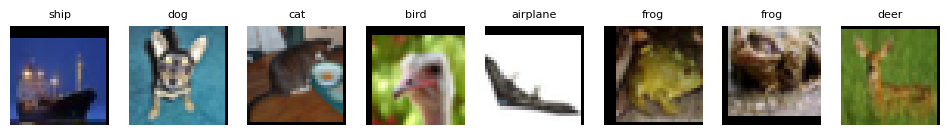

In [4]:
X_all_gpu, y_all_gpu = X_all.to(DEVICE), y_all.to(DEVICE)
X_test_gpu, y_test_gpu = X_test.to(DEVICE), y_test.to(DEVICE)


def take(idx, test=False):
    X, y = (X_test_gpu, y_test_gpu) if test else (X_all_gpu, y_all_gpu)
    idx = idx.to(DEVICE)
    return X[idx], y[idx]


train_data, val_data, test_data = take(train_idx), take(val_idx), take(test_idx, test=True)
sub_data = {f: take(idx) for f, idx in subset_idx.items()}


def random_crop_flip(x, pad=4):
    n, c, h, w = x.shape
    x = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (n,), device=x.device)  # top-left corner of each crop
    j = torch.randint(0, 2 * pad + 1, (n,), device=x.device)
    rows = (i[:, None] + torch.arange(h, device=x.device))[:, None, :, None]
    cols = (j[:, None] + torch.arange(w, device=x.device))[:, None, None, :]
    batch = torch.arange(n, device=x.device)[:, None, None, None]
    chan = torch.arange(c, device=x.device)[None, :, None, None]
    x = x[batch, chan, rows, cols]
    flip = torch.rand(n, device=x.device) < 0.5
    return torch.where(flip[:, None, None, None], x.flip(3), x)


def channel_stats(X_uint8):
    x = X_uint8.float() / 255
    return x.mean(dim=(0, 2, 3)), x.std(dim=(0, 2, 3))


class Preprocess:
    # pixels in [0, 1], optional bilinear upsampling, then per-channel normalization
    def __init__(self, mean, std, size=32):
        self.mean = torch.as_tensor(mean, device=DEVICE).view(1, 3, 1, 1)
        self.std = torch.as_tensor(std, device=DEVICE).view(1, 3, 1, 1)
        self.size = size

    def __call__(self, x):
        if self.size != 32:
            x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std


def batches(X, y, batch_size, shuffle=False, augment=False, gen=None):
    order = torch.randperm(len(y), generator=gen).to(DEVICE) if shuffle else torch.arange(len(y), device=DEVICE)
    for start in range(0, len(y), batch_size):
        idx = order[start:start + batch_size]
        xb = X[idx].float() / 255
        if augment:
            xb = random_crop_flip(xb)
        yield xb, y[idx]


# visual check of the augmentation
xb, yb = next(batches(*train_data, 8, shuffle=True, augment=True, gen=torch.Generator().manual_seed(0)))
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for ax, img, label in zip(axes, xb.cpu(), yb.cpu()):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(CLASSES[label], fontsize=8)
    ax.axis("off")
plt.show()

## 3. Models and training helpers

The CNN and the fine-tuned ResNet go through the same training loop, the same split and the same model selection (best validation accuracy), so the comparison is fair. Learning rate schedulers step after every batch. The frozen ResNet is the exception: its features never change, so I compute them once and only train the last layer on them (section 5.1).

In [5]:
def conv_block(c_in, c_out, p_drop):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
        nn.Dropout(p_drop),
    )


class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 64, 0.1),     # 32x32 to 16x16
            conv_block(64, 128, 0.1),   # 16x16 to 8x8
            conv_block(128, 256, 0.2),  # 8x8 to 4x4
        )
        self.classifier = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet18(n_classes=10):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, n_classes)  # new last layer, 512 to 10
    return model


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)


print(f"SmallCNN:  {count_params(SmallCNN()):,} parameters")
print(f"ResNet-18: {count_params(build_resnet18()):,} parameters")

SmallCNN:  1,148,874 parameters
ResNet-18: 11,181,642 parameters


In [6]:
def cnn_optimizer(model, total_steps):
    opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, total_steps=total_steps)
    return opt, sched


def finetune_optimizer(model, total_steps):
    backbone = [p for name, p in model.named_parameters() if not name.startswith("fc.")]
    opt = torch.optim.AdamW([{"params": backbone, "lr": 1e-4},
                             {"params": model.fc.parameters(), "lr": 1e-3}], weight_decay=1e-4)
    warmup = max(1, total_steps // 8)  # 12.5% of the steps, one epoch when training for 8
    sched = torch.optim.lr_scheduler.SequentialLR(opt, [
        torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=warmup),
        torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, total_steps - warmup)),
    ], milestones=[warmup])
    return opt, sched


def train_one_epoch(model, X, y, prep, opt, sched, batch_size, gen):
    model.train()
    loss_sum = torch.zeros((), device=DEVICE)
    correct = torch.zeros((), device=DEVICE)
    for xb, yb in batches(X, y, batch_size, shuffle=True, augment=True, gen=gen):
        out = model(prep(xb))
        loss = F.cross_entropy(out, yb)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        sched.step()  # every batch
        loss_sum += loss.detach() * len(yb)
        correct += (out.argmax(1) == yb).sum()
    return loss_sum.item() / len(y), correct.item() / len(y)


@torch.no_grad()
def evaluate(model, X, y, prep, batch_size=500):
    model.eval()
    loss_sum, preds = 0.0, []
    for xb, yb in batches(X, y, batch_size):
        out = model(prep(xb))
        loss_sum += F.cross_entropy(out, yb, reduction="sum").item()
        preds.append(out.argmax(1))
    preds = torch.cat(preds)
    return loss_sum / len(y), (preds == y).float().mean().item(), preds


@torch.no_grad()
def throughput(model, X, prep, batch_size=128, n_batches=20):
    # inference speed in images per second
    model.eval()
    xb = X[:batch_size].float() / 255
    for _ in range(3):
        model(prep(xb))
    sync()
    t0 = time.perf_counter()
    for _ in range(n_batches):
        model(prep(xb))
    sync()
    return batch_size * n_batches / (time.perf_counter() - t0)


def test_metrics(y, preds):
    y, preds = y.cpu(), preds.cpu()
    cm = torch.bincount(y * 10 + preds, minlength=100).reshape(10, 10)  # rows: true class, columns: predicted
    return cm.tolist(), (cm.diag() / cm.sum(1)).tolist()


def log(msg):
    print(msg)
    with open(LOG_FILE, "a") as f:
        f.write(f"{time.strftime('%H:%M:%S')} {msg}\n")


def epoch_line(run_id, r):
    line = f"{run_id} | epoch {r['epoch']:3d} | train loss {r['train_loss']:.4f} acc {r['train_acc']:.4f}"
    if r["val_acc"] is not None:
        line += f" | val loss {r['val_loss']:.4f} acc {r['val_acc']:.4f}"
    return line + f" | {r['epoch_time_s']:.1f}s"

In [7]:
def train_supervised(run_id, model_name, train_data, epochs, batch_size, seed, size=32, eval_every=1):
    set_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    X_tr, y_tr = train_data
    if model_name == "cnn":
        model = SmallCNN().to(DEVICE)
        prep = Preprocess(*channel_stats(X_tr))  # statistics of the images this run trains on
        make_opt = cnn_optimizer
    else:
        model = build_resnet18().to(DEVICE)
        prep = Preprocess(IMAGENET_MEAN, IMAGENET_STD, size=size)  # statistics the weights were trained with
        make_opt = finetune_optimizer
    opt, sched = make_opt(model, epochs * math.ceil(len(y_tr) / batch_size))

    history, best_acc, best_epoch, best_state, train_time = [], -1.0, None, None, 0.0
    for epoch in range(1, epochs + 1):
        sync()
        t0 = time.perf_counter()
        train_loss, train_acc = train_one_epoch(model, X_tr, y_tr, prep, opt, sched, batch_size, gen)
        sync()
        dt = time.perf_counter() - t0
        train_time += dt
        row = {"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc, "val_loss": None, "val_acc": None,
               "lr": max(g["lr"] for g in opt.param_groups), "epoch_time_s": dt}
        if epoch % eval_every == 0 or epoch == epochs:
            row["val_loss"], row["val_acc"], _ = evaluate(model, *val_data, prep)
            if row["val_acc"] > best_acc:
                best_acc, best_epoch = row["val_acc"], epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            log(epoch_line(run_id, row))
        history.append(row)

    torch.save(best_state, CKPT_DIR / f"{run_id}.pt")
    model.load_state_dict(best_state)
    test_loss, test_acc, preds = evaluate(model, *test_data, prep)
    cm, per_class = test_metrics(test_data[1], preds)
    result = {
        "model": model_name, "size": size, "n_train": len(y_tr), "epochs": epochs, "batch_size": batch_size,
        "seed": seed, "eval_every": eval_every, "history": history,
        "best_epoch": best_epoch, "best_val_acc": best_acc, "test_loss": test_loss, "test_acc": test_acc,
        "per_class_acc": per_class, "confusion": cm, "train_time_s": train_time,
        "params_total": count_params(model), "params_trainable": count_params(model, trainable_only=True),
        "throughput_img_s": throughput(model, test_data[0], prep),
    }
    del model, opt, sched, best_state
    return result


def run_experiment(run_id, train_fn, **kwargs):
    path = RESULTS_DIR / f"{run_id}.json"
    if path.exists():
        result = json.loads(path.read_text())
        print(f"{run_id}: already trained, epoch log loaded from {path.name}")
        for row in result["history"]:
            if row["val_acc"] is not None:
                print(epoch_line(run_id, row))
    else:
        log(f"{run_id}: training")
        result = train_fn(run_id, **kwargs)
        result["run_id"] = run_id
        tmp = path.with_suffix(".tmp")
        tmp.write_text(json.dumps(result))
        tmp.replace(path)  # a crash never leaves half a file behind
        gc.collect()
        if DEVICE.type == "mps":
            torch.mps.empty_cache()
    log(f"{run_id}: test accuracy {result['test_acc']:.4f} (best val {result['best_val_acc']:.4f} at epoch "
        f"{result['best_epoch']}) | training time {result['train_time_s'] / 60:.1f} min")
    return result

## 4. Part 1: CNN trained from scratch

Three blocks of two 3x3 convolutions with batch normalization, followed by max pooling and dropout (64, 128 and 256 channels). A global average pooling replaces a big dense layer at the end, which keeps the model at about 1.15M parameters. The dropout is lower in the first two blocks because neighboring pixels are strongly correlated there and element-wise dropout does little.

Training: SGD with Nesterov momentum, weight decay 5e-4, a one-cycle learning rate that peaks at 0.1, batches of 128, 30 epochs. I do not use label smoothing: with 10 classes and a factor of 0.1, the training loss could not go below about 0.50, and the training and validation curves would no longer be comparable. The run is repeated with 3 seeds.

In [8]:
cnn_runs = []
for seed in SEEDS:
    cnn_runs.append(run_experiment(f"E3_cnn_s{seed}", train_supervised, model_name="cnn",
                                   train_data=train_data, epochs=n_epochs(30), batch_size=128, seed=seed))

E3_cnn_s0: already trained, epoch log loaded from E3_cnn_s0.json
E3_cnn_s0 | epoch   1 | train loss 1.3804 acc 0.4992 | val loss 1.2960 acc 0.5710 | 27.6s
E3_cnn_s0 | epoch   2 | train loss 0.9572 acc 0.6611 | val loss 1.0523 acc 0.6534 | 28.3s
E3_cnn_s0 | epoch   3 | train loss 0.8039 acc 0.7173 | val loss 1.0356 acc 0.6626 | 36.5s
E3_cnn_s0 | epoch   4 | train loss 0.7125 acc 0.7521 | val loss 1.0358 acc 0.6946 | 34.1s
E3_cnn_s0 | epoch   5 | train loss 0.6314 acc 0.7807 | val loss 0.7090 acc 0.7684 | 36.2s
E3_cnn_s0 | epoch   6 | train loss 0.5828 acc 0.8000 | val loss 0.6642 acc 0.7766 | 33.7s
E3_cnn_s0 | epoch   7 | train loss 0.5391 acc 0.8154 | val loss 0.7497 acc 0.7542 | 35.7s
E3_cnn_s0 | epoch   8 | train loss 0.5062 acc 0.8257 | val loss 1.0110 acc 0.7094 | 37.9s
E3_cnn_s0 | epoch   9 | train loss 0.4790 acc 0.8341 | val loss 1.2184 acc 0.6590 | 37.0s
E3_cnn_s0 | epoch  10 | train loss 0.4576 acc 0.8420 | val loss 0.7211 acc 0.7670 | 36.3s
E3_cnn_s0 | epoch  11 | train loss 

### 4.1 Is 30 epochs enough?

If the CNN loses to ResNet-18 only because it trains for too few epochs, the comparison is unfair. With a one-cycle schedule the accuracy always climbs at the end (the learning rate goes to almost zero), so a rising curve at epoch 30 does not tell much. Instead I train the same CNN once for 60 epochs, with its own one-cycle schedule over the 60 epochs, and compare it with seed 0 of the 30 epoch runs.

In [9]:
cnn60 = run_experiment("E9_cnn60_s0", train_supervised, model_name="cnn", train_data=train_data,
                       epochs=n_epochs(60), batch_size=128, seed=0)
cnn30 = cnn_runs[0]
print(f"30 epochs: test accuracy {cnn30['test_acc']:.4f} in {cnn30['train_time_s'] / 60:.1f} min")
print(f"60 epochs: test accuracy {cnn60['test_acc']:.4f} in {cnn60['train_time_s'] / 60:.1f} min")
print(f"gain from doubling the training: {(cnn60['test_acc'] - cnn30['test_acc']) * 100:+.2f} points")

E9_cnn60_s0: already trained, epoch log loaded from E9_cnn60_s0.json
E9_cnn60_s0 | epoch   1 | train loss 1.3839 acc 0.4981 | val loss 1.2482 acc 0.5670 | 25.5s
E9_cnn60_s0 | epoch   2 | train loss 0.9637 acc 0.6588 | val loss 0.9605 acc 0.6680 | 25.9s
E9_cnn60_s0 | epoch   3 | train loss 0.8133 acc 0.7141 | val loss 1.2044 acc 0.6206 | 31.9s
E9_cnn60_s0 | epoch   4 | train loss 0.7258 acc 0.7494 | val loss 1.0102 acc 0.6894 | 35.0s
E9_cnn60_s0 | epoch   5 | train loss 0.6535 acc 0.7741 | val loss 0.7949 acc 0.7420 | 29.8s
E9_cnn60_s0 | epoch   6 | train loss 0.6070 acc 0.7902 | val loss 0.6878 acc 0.7686 | 29.3s
E9_cnn60_s0 | epoch   7 | train loss 0.5647 acc 0.8054 | val loss 0.7053 acc 0.7662 | 27.9s
E9_cnn60_s0 | epoch   8 | train loss 0.5302 acc 0.8163 | val loss 0.7683 acc 0.7604 | 39.6s
E9_cnn60_s0 | epoch   9 | train loss 0.5020 acc 0.8262 | val loss 1.1809 acc 0.6638 | 27.9s
E9_cnn60_s0 | epoch  10 | train loss 0.4721 acc 0.8366 | val loss 0.5611 acc 0.8062 | 28.7s
E9_cnn60_s0

## 5. Part 2: transfer learning with ResNet-18

ResNet-18 with the ImageNet weights (`IMAGENET1K_V1`), with the last layer replaced by a 512 to 10 linear layer. The images are upsampled on the GPU with bilinear interpolation (the same as the official transforms of these weights) and normalized with the ImageNet statistics, since those are the ones the weights were trained with.

### 5.1 Frozen network (linear probe), 128x128

Only the new last layer learns. The frozen network stays in `eval()` mode, otherwise batch normalization would overwrite the ImageNet statistics. Since the features never change, I extract them once for all 60,000 images and train the last layer on the 512-dimension vectors (AdamW, 30 epochs). Most of the cost of this approach is the extraction, so the training time reported includes the extraction time of the training images. There is no augmentation in this mode.

In [10]:
FEATURE_FILE = CKPT_DIR / "resnet18_features_128.pt"
_features = None


@torch.no_grad()
def extract_features(backbone, X, prep, batch_size=500):
    backbone.eval()
    feats = []
    for start in range(0, len(X), batch_size):
        feats.append(backbone(prep(X[start:start + batch_size].float() / 255)))
    return torch.cat(feats)


def get_features():
    # 512-d features of the frozen ResNet-18 for the 50,000 training and 10,000 test images, computed once
    global _features
    if _features is None:
        if FEATURE_FILE.exists():
            _features = torch.load(FEATURE_FILE, weights_only=True)
        else:
            backbone = build_resnet18().to(DEVICE)
            for p in backbone.parameters():
                p.requires_grad = False  # frozen: the pre-trained weights never change
            backbone.fc = nn.Identity()
            prep = Preprocess(IMAGENET_MEAN, IMAGENET_STD, size=128)
            sync()
            t0 = time.perf_counter()
            train_f = extract_features(backbone, X_all_gpu, prep)
            test_f = extract_features(backbone, X_test_gpu, prep)
            sync()
            secs = time.perf_counter() - t0
            _features = {"train": train_f.cpu(), "test": test_f.cpu(),
                         "sec_per_image": secs / (len(train_f) + len(test_f))}
            torch.save(_features, FEATURE_FILE)
            del backbone
    return _features


def train_probe(run_id, idx, epochs, seed, batch_size=256, eval_every=1):
    set_seed(seed)
    gen = torch.Generator().manual_seed(seed)
    feats = get_features()
    F_tr, y_tr = feats["train"][idx].to(DEVICE), y_all[idx].to(DEVICE)
    F_va, y_va = feats["train"][val_idx].to(DEVICE), y_all[val_idx].to(DEVICE)
    F_te, y_te = feats["test"][test_idx].to(DEVICE), y_test[test_idx].to(DEVICE)

    head = nn.Linear(512, 10).to(DEVICE)
    opt = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * math.ceil(len(y_tr) / batch_size))

    history, best_acc, best_epoch, best_state, train_time = [], -1.0, None, None, 0.0
    for epoch in range(1, epochs + 1):
        head.train()
        sync()
        t0 = time.perf_counter()
        order = torch.randperm(len(y_tr), generator=gen).to(DEVICE)
        loss_sum, correct = 0.0, 0
        for start in range(0, len(y_tr), batch_size):
            i = order[start:start + batch_size]
            out = head(F_tr[i])
            loss = F.cross_entropy(out, y_tr[i])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            sched.step()
            loss_sum += loss.item() * len(i)
            correct += (out.argmax(1) == y_tr[i]).sum().item()
        sync()
        dt = time.perf_counter() - t0
        train_time += dt
        row = {"epoch": epoch, "train_loss": loss_sum / len(y_tr), "train_acc": correct / len(y_tr),
               "val_loss": None, "val_acc": None, "lr": opt.param_groups[0]["lr"], "epoch_time_s": dt}
        if epoch % eval_every == 0 or epoch == epochs:
            head.eval()
            with torch.no_grad():
                out = head(F_va)
            row["val_loss"] = F.cross_entropy(out, y_va).item()
            row["val_acc"] = (out.argmax(1) == y_va).float().mean().item()
            if row["val_acc"] > best_acc:
                best_acc, best_epoch = row["val_acc"], epoch
                best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}
            log(epoch_line(run_id, row))
        history.append(row)

    head.load_state_dict(best_state)
    head.eval()
    with torch.no_grad():
        out = head(F_te)
    preds = out.argmax(1)
    cm, per_class = test_metrics(y_te, preds)

    full = build_resnet18().to(DEVICE)  # frozen backbone + trained head, only to measure inference speed
    for p in full.parameters():
        p.requires_grad = False
    full.fc = head  # the only trainable layer
    extraction_s = feats["sec_per_image"] * len(y_tr)
    result = {
        "model": "resnet18_frozen", "size": 128, "n_train": len(y_tr), "epochs": epochs, "batch_size": batch_size,
        "seed": seed, "eval_every": eval_every, "history": history,
        "best_epoch": best_epoch, "best_val_acc": best_acc,
        "test_loss": F.cross_entropy(out, y_te).item(), "test_acc": (preds == y_te).float().mean().item(),
        "per_class_acc": per_class, "confusion": cm,
        "train_time_s": extraction_s + train_time, "feature_extraction_s": extraction_s, "head_train_time_s": train_time,
        "params_total": count_params(full), "params_trainable": count_params(full, trainable_only=True),
        "throughput_img_s": throughput(full, test_data[0], Preprocess(IMAGENET_MEAN, IMAGENET_STD, size=128)),
    }
    del full, head, opt, sched
    return result


probe_runs = []
for seed in SEEDS:
    probe_runs.append(run_experiment(f"E4_probe128_f100_s{seed}", train_probe, idx=train_idx,
                                     epochs=n_epochs(30), seed=seed))

E4_probe128_f100_s0: already trained, epoch log loaded from E4_probe128_f100_s0.json
E4_probe128_f100_s0 | epoch   1 | train loss 0.7280 acc 0.7672 | val loss 0.4982 acc 0.8324 | 0.4s
E4_probe128_f100_s0 | epoch   2 | train loss 0.4596 acc 0.8452 | val loss 0.4494 acc 0.8460 | 0.2s
E4_probe128_f100_s0 | epoch   3 | train loss 0.4253 acc 0.8558 | val loss 0.4306 acc 0.8530 | 0.2s
E4_probe128_f100_s0 | epoch   4 | train loss 0.4081 acc 0.8602 | val loss 0.4199 acc 0.8558 | 0.2s
E4_probe128_f100_s0 | epoch   5 | train loss 0.3965 acc 0.8632 | val loss 0.4161 acc 0.8560 | 0.2s
E4_probe128_f100_s0 | epoch   6 | train loss 0.3871 acc 0.8672 | val loss 0.4139 acc 0.8564 | 0.2s
E4_probe128_f100_s0 | epoch   7 | train loss 0.3810 acc 0.8687 | val loss 0.4145 acc 0.8552 | 0.2s
E4_probe128_f100_s0 | epoch   8 | train loss 0.3762 acc 0.8701 | val loss 0.4090 acc 0.8598 | 0.2s
E4_probe128_f100_s0 | epoch   9 | train loss 0.3715 acc 0.8721 | val loss 0.4049 acc 0.8628 | 0.2s
E4_probe128_f100_s0 | ep

### 5.2 Full fine-tuning at 32 and 128 pixels

All layers learn. The pre-trained layers get a learning rate of 1e-4 and the new layer 1e-3 (AdamW), with one epoch of linear warm-up and then a cosine decay, 8 epochs in total. At 128 pixels, 8 epochs take about the same time as the 30 epochs of the CNN, so the comparison is also close to equal compute. At 32 pixels (the native size) the last feature map of ResNet-18 is only 1x1, so I expect it to lose a good part of its advantage.

In [11]:
ft_runs = {}
for size, exp in [(32, "E5"), (128, "E6")]:
    ft_runs[size] = []
    for seed in SEEDS:
        ft_runs[size].append(run_experiment(f"{exp}_ft{size}_s{seed}", train_supervised, model_name="resnet18",
                                            train_data=train_data, epochs=n_epochs(8), batch_size=128,
                                            seed=seed, size=size))

E5_ft32_s0: already trained, epoch log loaded from E5_ft32_s0.json
E5_ft32_s0 | epoch   1 | train loss 1.5581 acc 0.4484 | val loss 1.0234 acc 0.6470 | 18.9s
E5_ft32_s0 | epoch   2 | train loss 0.8997 acc 0.6872 | val loss 0.7745 acc 0.7306 | 18.6s
E5_ft32_s0 | epoch   3 | train loss 0.7280 acc 0.7469 | val loss 0.6834 acc 0.7626 | 19.6s
E5_ft32_s0 | epoch   4 | train loss 0.6447 acc 0.7765 | val loss 0.6271 acc 0.7822 | 20.9s
E5_ft32_s0 | epoch   5 | train loss 0.5740 acc 0.7992 | val loss 0.5972 acc 0.7982 | 21.1s
E5_ft32_s0 | epoch   6 | train loss 0.5223 acc 0.8170 | val loss 0.5860 acc 0.8020 | 20.1s
E5_ft32_s0 | epoch   7 | train loss 0.4854 acc 0.8294 | val loss 0.5790 acc 0.8060 | 20.3s
E5_ft32_s0 | epoch   8 | train loss 0.4774 acc 0.8314 | val loss 0.5786 acc 0.8092 | 20.0s
E5_ft32_s0: test accuracy 0.8147 (best val 0.8092 at epoch 8) | training time 2.7 min
E5_ft32_s1: already trained, epoch log loaded from E5_ft32_s1.json
E5_ft32_s1 | epoch   1 | train loss 1.5402 acc 0.456

### 5.3 Full fine-tuning at 224 pixels

224 is the size ResNet-18 was pre-trained on. Upsampling a 32x32 image to 224x224 adds no detail (the image is blurry), but the network sees objects at the scale it learned on ImageNet. One run costs about 3.5 times the 128 pixel run.

In [12]:
ft_runs[224] = []
for seed in E7_SEEDS:
    ft_runs[224].append(run_experiment(f"E7_ft224_s{seed}", train_supervised, model_name="resnet18",
                                       train_data=train_data, epochs=n_epochs(8), batch_size=128,
                                       seed=seed, size=224))

E7_ft224_s0: already trained, epoch log loaded from E7_ft224_s0.json
E7_ft224_s0 | epoch   1 | train loss 0.6317 acc 0.7990 | val loss 0.2295 acc 0.9212 | 518.0s
E7_ft224_s0 | epoch   2 | train loss 0.1910 acc 0.9357 | val loss 0.1972 acc 0.9312 | 480.2s
E7_ft224_s0 | epoch   3 | train loss 0.1165 acc 0.9594 | val loss 0.1529 acc 0.9468 | 515.7s
E7_ft224_s0 | epoch   4 | train loss 0.0757 acc 0.9741 | val loss 0.1450 acc 0.9512 | 531.4s
E7_ft224_s0 | epoch   5 | train loss 0.0457 acc 0.9853 | val loss 0.1349 acc 0.9566 | 529.8s
E7_ft224_s0 | epoch   6 | train loss 0.0266 acc 0.9924 | val loss 0.1170 acc 0.9618 | 519.9s
E7_ft224_s0 | epoch   7 | train loss 0.0194 acc 0.9946 | val loss 0.1218 acc 0.9608 | 536.1s
E7_ft224_s0 | epoch   8 | train loss 0.0155 acc 0.9957 | val loss 0.1206 acc 0.9610 | 520.6s
E7_ft224_s0: test accuracy 0.9581 (best val 0.9618 at epoch 6) | training time 69.2 min
E7_ft224_s1: already trained, epoch log loaded from E7_ft224_s1.json
E7_ft224_s1 | epoch   1 | trai

## 6. How much data does each approach need?

Same three models (CNN, frozen ResNet, fine-tuned ResNet at 128 pixels) trained on 1% and 10% of the training images (450 and 4,500), with the same validation and test sets. The 100% points are the runs of sections 4 and 5. With very few images, the number of optimization steps matters more than the number of epochs, so I set a step budget instead of reusing the same epoch count: about 1,500 steps for the CNN, 50 epochs (1%) and 15 epochs (10%) for the fine-tuned ResNet, and 200 or 50 epochs for the frozen ResNet. Validation is checked every 10 epochs (1%) or 5 epochs (10%) to save time.

Kornblith et al. (2019, "Do Better ImageNet Models Transfer Better?", section 4.7) found that with very small datasets, a frozen network with a logistic regression on top can match or beat fine-tuning. This section checks if that holds on CIFAR-10.

In [13]:
FRACTIONS = {
    0.01: dict(batch_size=64, ft_epochs=50, probe_epochs=200, eval_every=10),
    0.10: dict(batch_size=128, ft_epochs=15, probe_epochs=50, eval_every=5),
}
CNN_STEPS = 1500

for frac, cfg in FRACTIONS.items():
    tag = f"f{round(frac * 100)}"
    steps_per_epoch = math.ceil(len(subset_idx[frac]) / cfg["batch_size"])
    eval_every = 1 if SMOKE else cfg["eval_every"]
    for seed in SEEDS:
        run_experiment(f"E8_cnn_{tag}_s{seed}", train_supervised, model_name="cnn", train_data=sub_data[frac],
                       epochs=n_epochs(math.ceil(CNN_STEPS / steps_per_epoch)), batch_size=cfg["batch_size"],
                       seed=seed, eval_every=eval_every)
        run_experiment(f"E8_ft128_{tag}_s{seed}", train_supervised, model_name="resnet18", train_data=sub_data[frac],
                       epochs=n_epochs(cfg["ft_epochs"]), batch_size=cfg["batch_size"], seed=seed, size=128,
                       eval_every=eval_every)
        run_experiment(f"E4_probe128_{tag}_s{seed}", train_probe, idx=subset_idx[frac],
                       epochs=n_epochs(cfg["probe_epochs"]), batch_size=cfg["batch_size"], seed=seed,
                       eval_every=eval_every)

E8_cnn_f1_s0: already trained, epoch log loaded from E8_cnn_f1_s0.json
E8_cnn_f1_s0 | epoch  10 | train loss 2.0165 acc 0.2533 | val loss 2.2576 acc 0.2324 | 0.4s
E8_cnn_f1_s0 | epoch  20 | train loss 2.0722 acc 0.3089 | val loss 2.6072 acc 0.2724 | 0.3s
E8_cnn_f1_s0 | epoch  30 | train loss 1.9862 acc 0.2467 | val loss 2.7265 acc 0.2118 | 0.4s
E8_cnn_f1_s0 | epoch  40 | train loss 1.6489 acc 0.3756 | val loss 2.2252 acc 0.2474 | 0.3s
E8_cnn_f1_s0 | epoch  50 | train loss 1.8372 acc 0.3044 | val loss 2.1198 acc 0.2652 | 0.3s
E8_cnn_f1_s0 | epoch  60 | train loss 1.7267 acc 0.3222 | val loss 2.1158 acc 0.2574 | 0.3s
E8_cnn_f1_s0 | epoch  70 | train loss 1.6087 acc 0.3933 | val loss 2.2111 acc 0.2926 | 0.3s
E8_cnn_f1_s0 | epoch  80 | train loss 1.3376 acc 0.4933 | val loss 2.3075 acc 0.3052 | 0.3s
E8_cnn_f1_s0 | epoch  90 | train loss 1.3060 acc 0.5022 | val loss 1.8964 acc 0.3792 | 0.3s
E8_cnn_f1_s0 | epoch 100 | train loss 1.4172 acc 0.4733 | val loss 1.9752 acc 0.3498 | 0.3s
E8_cnn_f1

## 7. Results (Part 3)

Every number below is read back from the JSON files, so this section can run on its own once the runs are done. Accuracies are on the 10,000 test images, as mean ± standard deviation over the seeds. For ResNet-18 only the accuracy is reported, as the assignment asks.

### 7.1 Comparison table

Final accuracy alone hides how fast each model gets there, so the table also gives the training time needed to first reach 85% validation accuracy. I fixed the 85% threshold before looking at any result. For the frozen ResNet, the clock starts with the feature extraction of the training images.

In [14]:
def load_runs(prefix):
    return [json.loads(p.read_text()) for p in sorted(RESULTS_DIR.glob(f"{prefix}_s*.json"))]


def mean_std(values):
    values = np.array(values, dtype=float)
    return values.mean(), (values.std(ddof=1) if len(values) > 1 else 0.0)


THRESHOLD = 0.85


def minutes_to_reach(run, threshold=THRESHOLD):
    # training time until the first validation check at or above the threshold, None if never reached
    elapsed = run.get("feature_extraction_s", 0.0)
    for row in run["history"]:
        elapsed += row["epoch_time_s"]
        if row["val_acc"] is not None and row["val_acc"] >= threshold:
            return elapsed / 60
    return None


def time_to_reach_label(runs):
    times = [minutes_to_reach(r) for r in runs]
    reached = [t for t in times if t is not None]
    if not reached:
        return "not reached"
    label = f"{np.mean(reached):.1f}"
    return label if len(reached) == len(times) else f"{label} ({len(reached)}/{len(times)} seeds)"


ROWS = [
    ("CNN from scratch", "all layers, 32 px", "E3_cnn"),
    ("CNN from scratch", "all layers, 32 px, 60 epochs", "E9_cnn60"),
    ("ResNet-18", "frozen, last layer only, 128 px", "E4_probe128_f100"),
    ("ResNet-18", "full fine-tuning, 32 px", "E5_ft32"),
    ("ResNet-18", "full fine-tuning, 128 px", "E6_ft128"),
    ("ResNet-18", "full fine-tuning, 224 px", "E7_ft224"),
]
table = []
for model, strategy, prefix in ROWS:
    runs = load_runs(prefix)
    if not runs:
        continue
    acc_mean, acc_std = mean_std([r["test_acc"] * 100 for r in runs])
    table.append({
        "Model": model, "Training": strategy, "Seeds": len(runs),
        "Test accuracy (%)": f"{acc_mean:.2f} ± {acc_std:.2f}" if len(runs) > 1 else f"{acc_mean:.2f}",  # no std with 1 seed
        "Params (M)": round(runs[0]["params_total"] / 1e6, 2),
        "Trained params (M)": round(runs[0]["params_trainable"] / 1e6, 3),
        "Epochs": runs[0]["epochs"],
        "Training time per run (min)": round(np.mean([r["train_time_s"] for r in runs]) / 60, 1),
        f"Time to {THRESHOLD:.0%} val (min)": time_to_reach_label(runs),
        "Inference (img/s)": round(np.mean([r["throughput_img_s"] for r in runs])),
    })
results_table = pd.DataFrame(table)
results_table

,Model,Training,Seeds,Test accuracy (%),Params (M),Trained params (M),Epochs,Training time per run (min),Time to 85% val (min),Inference (img/s)
0,CNN from scratch,"all layers, 32 px",3,91.62 ± 0.12,1.15,1.149,30,16.0,10.4,4420
1,CNN from scratch,"all layers, 32 px, 60 epochs",1,92.29,1.15,1.149,60,28.9,18.4,4560
2,ResNet-18,"frozen, last layer only, 128 px",3,86.22 ± 0.19,11.18,0.005,30,0.7,0.7,1267
3,ResNet-18,"full fine-tuning, 32 px",3,81.39 ± 0.10,11.18,11.182,8,2.7,not reached,6279
4,ResNet-18,"full fine-tuning, 128 px",3,95.30 ± 0.13,11.18,11.182,8,19.0,2.3,1094
5,ResNet-18,"full fine-tuning, 224 px",3,95.92 ± 0.11,11.18,11.182,8,66.8,8.2,318


### 7.2 CNN training curves (loss and accuracy)

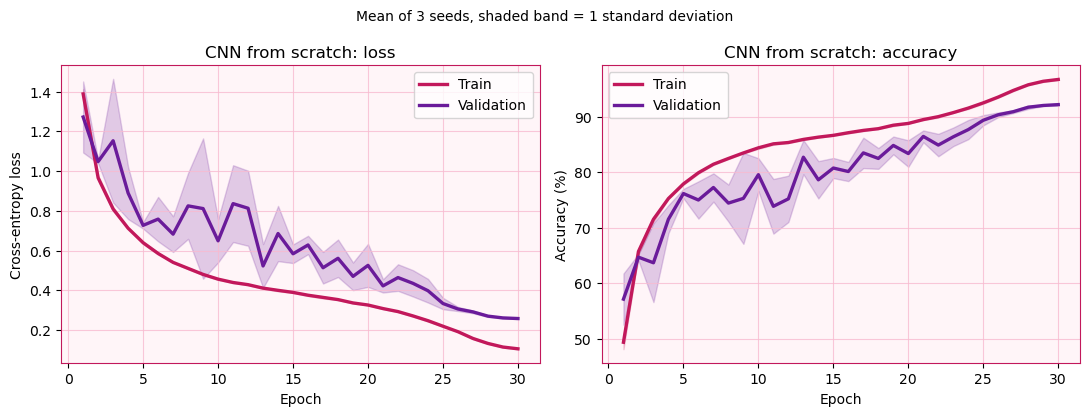

In [15]:
PINK, LIGHT_PINK, BG, PURPLE, GREY = "#C2185B", "#F8BBD0", "#FFF5F8", "#6A1B9A", "#546E7A"


def style(ax):
    ax.grid(True, color=LIGHT_PINK, alpha=0.8)
    ax.set_facecolor(BG)
    for sp in ax.spines.values():
        sp.set_color(PINK)


cnn = load_runs("E3_cnn")
ep = np.arange(1, len(cnn[0]["history"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, metric, ylabel, scale in [(axes[0], "loss", "Cross-entropy loss", 1), (axes[1], "acc", "Accuracy (%)", 100)]:
    for split, color, label in [("train", PINK, "Train"), ("val", PURPLE, "Validation")]:
        vals = np.array([[h[f"{split}_{metric}"] * scale for h in r["history"]] for r in cnn])
        mean = vals.mean(0)
        std = vals.std(0, ddof=1) if len(cnn) > 1 else np.zeros_like(mean)
        ax.plot(ep, mean, color=color, linewidth=2.4, label=label)
        ax.fill_between(ep, mean - std, mean + std, color=color, alpha=0.2)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    style(ax)
axes[0].set_title("CNN from scratch: loss")
axes[1].set_title("CNN from scratch: accuracy")
fig.suptitle(f"Mean of {len(cnn)} seeds, shaded band = 1 standard deviation", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_A_cnn_curves.png", dpi=200)
plt.show()

The training loss is measured with dropout and augmentation on, while the validation loss is measured in `eval()` mode on clean images, so a validation curve slightly above the training curve in accuracy (and below in loss) early on is expected.

### 7.3 Accuracy vs amount of training data

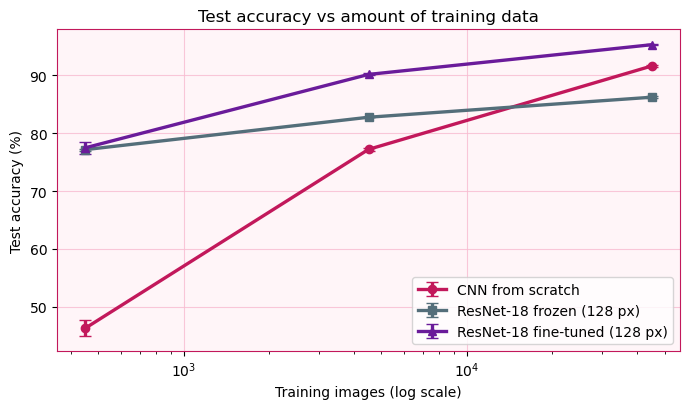

,Model,Training images,Seeds,Test accuracy (%)
0,CNN from scratch,450,3,46.32 ± 1.44
1,CNN from scratch,4500,3,77.21 ± 0.29
2,CNN from scratch,45000,3,91.62 ± 0.12
3,ResNet-18 frozen (128 px),450,3,77.17 ± 0.17
4,ResNet-18 frozen (128 px),4500,3,82.76 ± 0.04
5,ResNet-18 frozen (128 px),45000,3,86.22 ± 0.19
6,ResNet-18 fine-tuned (128 px),450,3,77.48 ± 1.05
7,ResNet-18 fine-tuned (128 px),4500,3,90.16 ± 0.17
8,ResNet-18 fine-tuned (128 px),45000,3,95.30 ± 0.13


In [16]:
SERIES = [
    ("CNN from scratch", ["E8_cnn_f1", "E8_cnn_f10", "E3_cnn"], PINK, "o"),
    ("ResNet-18 frozen (128 px)", ["E4_probe128_f1", "E4_probe128_f10", "E4_probe128_f100"], GREY, "s"),
    ("ResNet-18 fine-tuned (128 px)", ["E8_ft128_f1", "E8_ft128_f10", "E6_ft128"], PURPLE, "^"),
]
eff_rows = []
fig, ax = plt.subplots(figsize=(7, 4.2))
for label, prefixes, color, marker in SERIES:
    xs, means, stds = [], [], []
    for prefix in prefixes:
        runs = load_runs(prefix)
        if not runs:
            continue
        m, s = mean_std([r["test_acc"] * 100 for r in runs])
        xs.append(runs[0]["n_train"])
        means.append(m)
        stds.append(s)
        eff_rows.append({"Model": label, "Training images": runs[0]["n_train"], "Seeds": len(runs),
                         "Test accuracy (%)": f"{m:.2f} ± {s:.2f}"})
    ax.errorbar(xs, means, yerr=stds, color=color, marker=marker, linewidth=2.4, capsize=4, label=label)
ax.set_xscale("log")
ax.set_xlabel("Training images (log scale)")
ax.set_ylabel("Test accuracy (%)")
ax.set_title("Test accuracy vs amount of training data")
ax.legend()
style(ax)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_B_data_efficiency.png", dpi=200)
plt.show()
pd.DataFrame(eff_rows)

### 7.4 Where the models make mistakes

CNN from scratch: most confused pair is cat / dog (147 test images, both directions)
ResNet-18 (E7_ft224): most confused pair is cat / dog (96 test images, both directions)


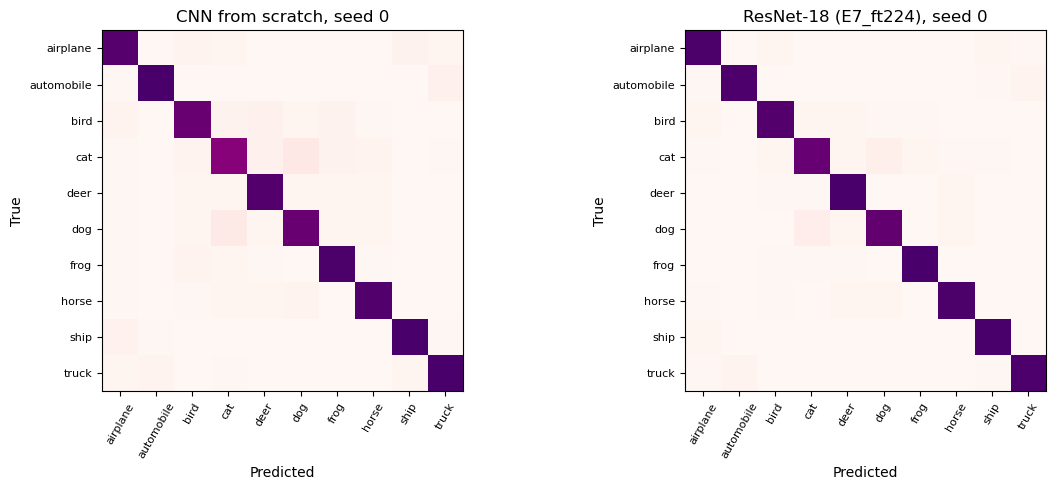

,CNN from scratch,ResNet-18 (E7_ft224)
airplane,92.6,97.0
automobile,95.7,96.9
bird,87.5,95.4
cat,80.7,90.2
deer,92.8,97.5
dog,87.8,91.5
frog,94.7,98.1
horse,93.4,97.1
ship,95.2,97.8
truck,95.2,96.6


In [17]:
def most_confused(cm):
    cm = np.array(cm)
    both_ways = cm + cm.T
    np.fill_diagonal(both_ways, 0)
    i, j = np.unravel_index(both_ways.argmax(), both_ways.shape)
    return CLASSES[i], CLASSES[j], int(both_ways[i, j])


best_ft = max(["E6_ft128", "E7_ft224"], key=lambda p: np.mean([r["test_acc"] for r in load_runs(p)] or [0]))
pairs = [("CNN from scratch", load_runs("E3_cnn")[0]), (f"ResNet-18 ({best_ft})", load_runs(best_ft)[0])]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, run) in zip(axes, pairs):
    cm = np.array(run["confusion"])
    ax.imshow(cm, cmap="RdPu")
    ax.set_xticks(range(10), CLASSES, rotation=60, fontsize=8)
    ax.set_yticks(range(10), CLASSES, fontsize=8)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{name}, seed 0")
    a, b, n = most_confused(cm)
    print(f"{name}: most confused pair is {a} / {b} ({n} test images, both directions)")
plt.tight_layout()
plt.show()

pd.DataFrame({name: np.round(np.array(run["per_class_acc"]) * 100, 1) for name, run in pairs}, index=CLASSES)

## 8. Discussion

Fine-tuned ResNet-18 is the most accurate model (95.30% at 128 pixels, 95.92% at 224), 3.7 to 4.3 points above the CNN (91.62%), and training the CNN for twice as many epochs only adds 0.7 points. Still, the frozen network (86.22%) and the fine-tuned network at its native 32x32 size (81.39%) both lose to the CNN: the pre-trained weights help most when the whole network can adapt and the images are upsampled closer to the size it learned on.

At 128 pixels the fine-tuned ResNet takes about as long per run as the CNN (19.0 vs 16.0 minutes) but reaches 85% validation accuracy in 2.3 minutes instead of 10.4. The CNN has almost 10 times fewer parameters and is 4 times faster at inference than ResNet-18 at 128 pixels. Going from 128 to 224 pixels buys 0.6 points for 3.5 times the training time.

With 450 training images the pre-trained models reach about 77% and the CNN 46%, and at that size the frozen network is as good as fine-tuning, which matches Kornblith et al. (2019). With 4,500 images fine-tuning is already 7.4 points ahead of the frozen network. The limitations are listed in the README.